# Road Features for the Crash Model

Checks the 6 road features before we model anything: does each one change the crash rate, how much is
missing, and do any of them overlap.

In [1]:
import json
from collections import Counter
import textwrap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

cwd = Path.cwd()
project_root = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
PROCESSED = project_root / "data" / "processed"

# Newest road cleaning run with the special-value columns from notebook 01
road_runs = sorted(PROCESSED.glob("boston_cleaning_*/roads_initial_clean_attributes.csv"))
road_path = next(p for p in reversed(road_runs)
                 if "aadt_is_default" in pd.read_csv(p, nrows=0).columns)

roads = pd.read_csv(road_path, low_memory=False)
labels = pd.read_csv(PROCESSED / "segment_labels.csv")[["segment_id", "had_crash", "near_ambiguous_crash"]]
df = roads.merge(labels, on="segment_id", how="inner")

## 1. Segments

We drop bike/pedestrian paths, and segments near an ambiguous crash, since we don't know if they had the crash.

In [2]:
df = df[~df["is_bike_ped_path"] & ~df["near_ambiguous_crash"]].reset_index(drop=True)
print(f"Segments: {len(df):,}")
print(f"With a crash: {df['had_crash'].sum():,} ({df['had_crash'].mean():.1%})")

Segments: 20,685
With a crash: 1,735 (8.4%)


Only 8.4% had a crash, so a model that always says "no crash" would be 92% accurate. That's why we'll
use PR-AUC instead of accuracy.

For each feature we split the segments into groups and graph the % of segments in each group that
had a crash. The dashed line is the overall rate (8.4%). If the bars move a lot away from that line,
the feature is worth using. The number under each bar is how many segments are in that group.

In [3]:
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
OVERALL = df["had_crash"].mean() * 100

def crash_rate(groups):
    out = df.groupby(groups, observed=True)["had_crash"].agg(segments="size", crash_rate="mean")
    out["crash_rate"] = (out["crash_rate"] * 100).round(1)
    return out

def group_name(g):
    if isinstance(g, pd.Interval):
        return f"{g.left:,.0f}–{g.right:,.0f}"
    return textwrap.fill(str(g), 14)

def finish(ax, title, xlabel):
    ax.axhline(OVERALL, color=GRAY, ls="--", lw=1)
    ax.text(1.01, OVERALL, f"all segments\n{OVERALL:.1f}%", transform=ax.get_yaxis_transform(),
            va="center", fontsize=9, color=GRAY)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% of segments with a crash")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

def plot_rate(table, title, xlabel):
    names = [f"{group_name(g)}\n({n:,})" for g, n in zip(table.index, table["segments"])]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    bars = ax.bar(names, table["crash_rate"], color=BLUE, width=0.6)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    finish(ax, title, xlabel)

## 2. Road type

Highways and side streets shouldn't have the same risk.

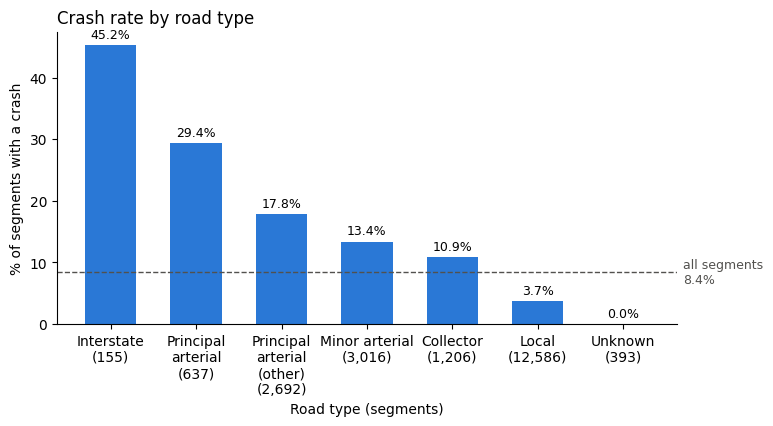

In [4]:
ROAD_TYPES = {0: "Local", 1: "Interstate", 2: "Principal arterial", 3: "Principal arterial (other)",
              5: "Minor arterial", 6: "Collector"}
df["road_type"] = df["F_Class"].map(ROAD_TYPES).fillna("Unknown")
plot_rate(crash_rate("road_type").sort_values("crash_rate", ascending=False),
          "Crash rate by road type", "Road type (segments)")

Interstates are at 45% and local streets at 4%. The 393 "Unknown" segments have no crashes at all.
They're probably not public roads, so we should check them before modeling.

## 3. Exposure (AADT × length)

More traffic and a longer segment both mean more chances for a crash. Roads with the 1,154 default AADT
keep it, so their length still counts.

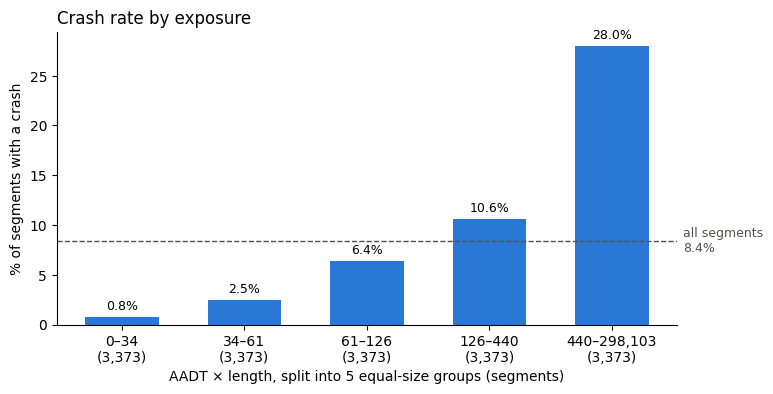

In [5]:
df["exposure"] = df["AADT"] * df["Length"]
plot_rate(crash_rate(pd.qcut(df["exposure"], 5)),
          "Crash rate by exposure", "AADT × length, split into 5 equal-size groups (segments)")

Goes up in every group, from 0.8% to 28%. This is the strongest feature.

## 4. Traffic counted

1 if the road has a real AADT, 0 if it's the 1,154 default or missing. MassDOT counts the roads that
matter for traffic, so this tells the model which exposure values are real.

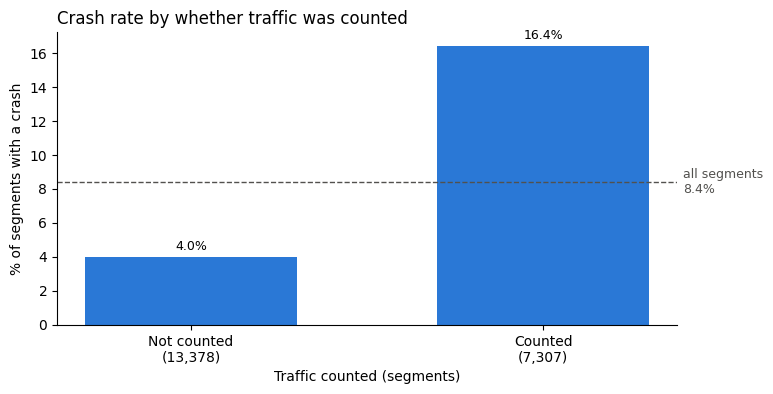

In [6]:
df["traffic_counted"] = df["aadt_clean"].notna().astype(int)
counted = crash_rate("traffic_counted").rename(index={0: "Not counted", 1: "Counted"})
plot_rate(counted, "Crash rate by whether traffic was counted", "Traffic counted (segments)")

16.4% for counted roads vs. 4.0% for the rest.

## 5. Sidewalks

Both sides, one side, none, or unknown, from the left and right sidewalk widths.

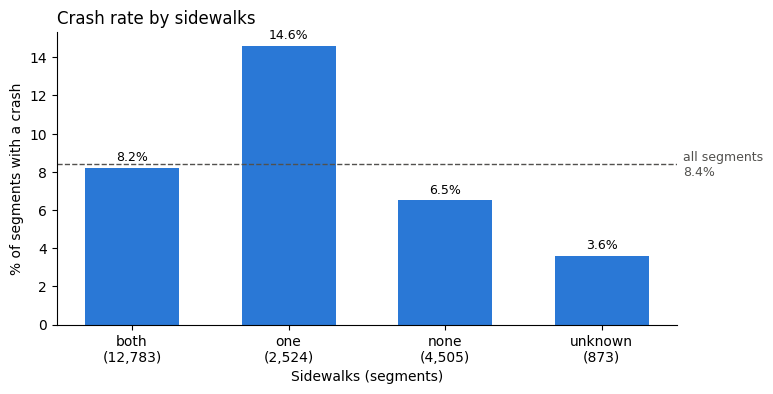

In [7]:
left, right = df["Lt_Sidewlk"], df["Rt_Sidewlk"]
df["sidewalks"] = np.select(
    [left.isna() | right.isna(), (left > 0) & (right > 0), (left > 0) | (right > 0)],
    ["unknown", "both", "one"],
    default="none",
)
plot_rate(crash_rate("sidewalks").loc[["both", "one", "none", "unknown"]],
          "Crash rate by sidewalks", "Sidewalks (segments)")

One side is the highest at 14.6%, which we didn't expect. It could be bridges or roads along a park
or the river.

## 6. Width

Road width in feet, with 0 treated as missing.

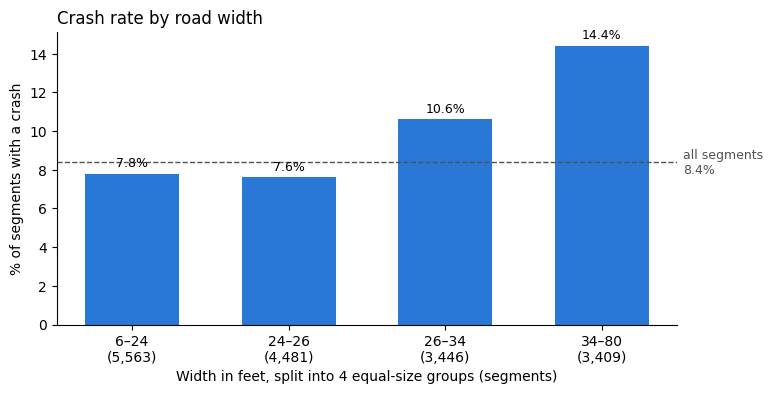

In [8]:
plot_rate(crash_rate(pd.qcut(df["surface_wd_clean"], 4, duplicates="drop")),
          "Crash rate by road width", "Width in feet, split into 4 equal-size groups (segments)")

Only goes up for roads wider than about 26 ft. The weakest pattern so far.

## 7. Connections

How many other road segments touch the two ends of a segment. We get this from the road line shapes:
take each segment's two end points (rounded to the nearest meter) and count how many other segments
share them. A side street that connects to a lot of other roads probably gets more traffic cutting
through it.

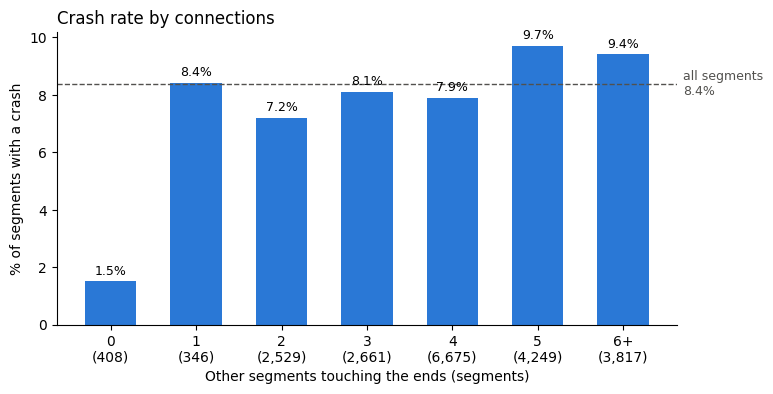

In [9]:
shapes = json.loads((road_path.parent / "retained_source_features_esri.json").read_text())

ends = {}
for f in shapes["features"]:
    paths = [p for p in f["geometry"]["paths"] if len(p) >= 2]
    start, end = paths[0][0], paths[-1][-1]
    ends[f["attributes"]["GlobalID"]] = [(round(start[0]), round(start[1])), (round(end[0]), round(end[1]))]

touching = Counter(pt for pair in ends.values() for pt in pair)
connections = {seg: touching[a] + touching[b] - 2 for seg, (a, b) in ends.items()}  # -2 so it doesn't count itself
df["connections"] = df["segment_id"].map(connections)

by_count = crash_rate(df["connections"].clip(upper=6)).rename(index={6: "6+"})
plot_rate(by_count, "Crash rate by connections", "Other segments touching the ends (segments)")

Overall it's pretty flat, around 8–9%. It only shows up when we split by road type:

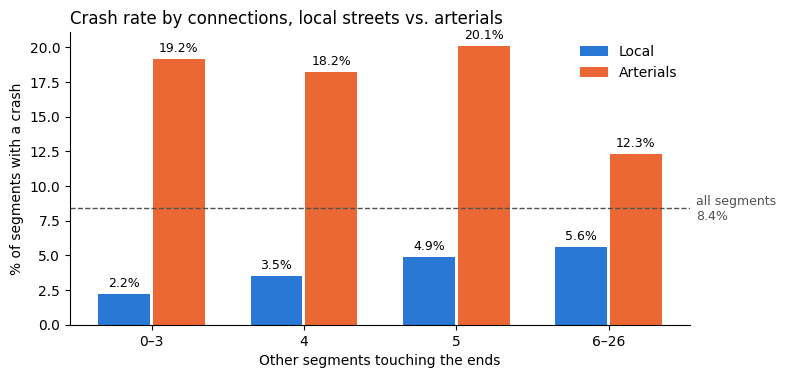

In [10]:
groups = pd.qcut(df["connections"], 4, duplicates="drop")
is_arterial = df["road_type"].str.contains("arterial")
split = pd.DataFrame({
    "Local": df[df["road_type"] == "Local"].groupby(groups, observed=True)["had_crash"].mean(),
    "Arterials": df[is_arterial].groupby(groups, observed=True)["had_crash"].mean(),
}).mul(100).round(1)
lows = [int(np.floor(g.left)) + 1 for g in split.index]
highs = [int(g.right) for g in split.index]
split.index = [str(lo) if lo == hi else f"{lo}–{hi}" for lo, hi in zip(lows, highs)]

x = np.arange(len(split))
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (name, color) in enumerate([("Local", BLUE), ("Arterials", ORANGE)]):
    bars = ax.bar(x + (i - 0.5) * 0.36, split[name], width=0.34, color=color, label=name)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_xticks(x, split.index)
ax.legend(frameon=False, loc="upper right")
finish(ax, "Crash rate by connections, local streets vs. arterials", "Other segments touching the ends")

On local streets, more connections means more crashes (about 2% → 6%). On arterials it stays around
18–20% and drops to 12% for the most connected ones. So this feature depends on road type. Random forest can pick that up on its own, but logistic
regression will need a connections × road type term, or the two effects cancel out.

## 8. Tried and dropped

We tested these too. They didn't add anything once we compared roads of the same type or length:
- **Lane width** (width ÷ lanes): the overall pattern was just road type showing through.
- **Curviness** (line length ÷ straight distance between the ends): "straight" segments were mostly
  short ones drawn with two points, so it was mostly length. With length held the same, curvier
  roads had fewer crashes, probably because they're quiet residential or park roads.
- **AADT per lane**: 65% missing and no clear pattern beyond exposure.
- **Sidewalk share of street width**: no pattern.

## 9. Overlap

Exposure, width, traffic counted, and connections all partly measure how big or busy a road is. If two
are almost the same, one isn't adding anything.

In [11]:
NUMERIC = ["exposure", "surface_wd_clean", "traffic_counted", "connections"]
df.groupby("road_type")[NUMERIC].median().round(1)

,exposure,surface_wd_clean,traffic_counted,connections
road_type,,,,
Collector,228.8,30.0,1.0,4.0
Interstate,4956.1,36.0,1.0,3.0
Local,54.9,26.0,0.0,4.0
Minor arterial,346.3,37.0,1.0,5.0
Principal arterial,743.8,24.0,1.0,4.0
Principal arterial (other),752.2,26.0,1.0,4.0
Unknown,6.5,26.0,0.0,1.0


In [12]:
df[NUMERIC + ["had_crash"]].corr(method="spearman").round(2)

,exposure,surface_wd_clean,traffic_counted,connections,had_crash
exposure,1.00,0.21,0.54,0.06,0.31
surface_wd_clean,0.21,1.00,0.37,0.18,0.09
traffic_counted,0.54,0.37,1.00,0.21,0.21
connections,0.06,0.18,0.21,1.00,0.03
had_crash,0.31,0.09,0.21,0.03,1.00


They're related, but none are close to 1, so each one still adds something.

## 10. Missing values

In [13]:
FEATURES = ["road_type", "exposure", "traffic_counted", "sidewalks", "surface_wd_clean", "connections"]
(df[FEATURES].isna().mean() * 100).round(1).rename("missing %")

road_type            0.0
exposure            18.5
traffic_counted      0.0
sidewalks            0.0
surface_wd_clean    18.3
connections          0.0
Name: missing %, dtype: float64

Exposure and width are each about 18% missing. Random forest can handle that directly. For logistic
regression we'll fill in the median from the training data and add a "was missing" flag.

## 11. Save

In [14]:
df[["segment_id", "OBJECTID"] + FEATURES + ["had_crash"]].to_csv(PROCESSED / "model_features.csv", index=False)

## Next

- Split train and test by area, not randomly, since nearby streets are similar.
- Train logistic regression (with log of exposure, 0/1 columns for the categories, and a connections ×
  road type term) and random forest.
- Compare PR-AUC on the test area.
- Add speed limit and other features one at a time to see if they help.